# Assignment 1 — Training pipeline: which cloud-kitchen concepts do well?

**Use case.** A cloud-kitchen (delivery-only) company wants to choose which **cuisine + price** concepts to launch in
Gurgaon and Noida. The model estimates, for a restaurant described by its cuisine(s), price, location and services,
the **probability that it is rated 3.8 or higher on Zomato** ("success").

**Hypothesis under test.** There is a price "sweet spot": customers judge expensive places more harshly and cheap
places more leniently, so success depends on price *relative to what is normal for that cuisine*, and possibly
differently for delivery restaurants.

**What this notebook does, top to bottom** (it must run start to finish with no manual steps, via
`uv run python main.py train`):

1. Load and clean the data (India only, rated restaurants, valid price).
2. Explore it: the target classes, price, cuisine and city patterns.
3. Split it into train / validation / test, keeping all outlets of a chain in the same split.
4. Engineer features (fitted on the training split only).
5. Train the same logistic regression three ways: **scikit-learn**, a **manual PyTorch loop**, and the
   **standard `nn.Module` + `torch.optim` workflow**, with tuning of regularisation strength and learning rate.
6. Compare the three against each other and against a naive baseline.
7. Pick a decision threshold from business costs, and look at the model's price sweet-spot curve.
8. Save everything the Gradio app (`app.py`) needs, so the app never retrains anything.

Shared code (cleaning, feature engineering and the PyTorch model class) lives in `pipeline.py`, so that the app
builds features in exactly the same way as this notebook.

## 0. Setup

In [1]:
# ---------------------------------------------------------------------------
# Imports
# ---------------------------------------------------------------------------
import json
from pathlib import Path

import joblib  # saves/loads scikit-learn objects (installed together with scikit-learn)
import matplotlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# ---------------------------------------------------------------------------
# Notebook vs. script
# ---------------------------------------------------------------------------
# `main.py train` converts this notebook to a plain Python script and runs it.
# In a plain script, plt.show() would try to open a window for every chart and
# wait for you to close it - that is a "manual step", which the assignment
# forbids. So: if we are NOT inside Jupyter, switch matplotlib to the
# non-interactive "Agg" backend (charts are only saved to files, nothing pops
# up). get_ipython() only exists inside Jupyter/IPython, so calling it tells
# us where we are.
try:
    get_ipython()  # noqa: F821  (defined by Jupyter)
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")

import matplotlib.pyplot as plt  # must be imported AFTER choosing the backend
from IPython.display import display  # pretty tables in Jupyter; plain text in a script

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix, log_loss,
    precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

import pipeline as P  # our shared cleaning / feature / model code

# ---------------------------------------------------------------------------
# Paths and constants
# ---------------------------------------------------------------------------
ROOT = Path.cwd()                      # main.py runs us from the repo root
DATA_PATH = ROOT / "data" / "zomato.csv"
ARTIFACT_DIR = ROOT / "artifacts"      # trained models + everything the app needs
FIG_DIR = ROOT / "figures"             # every chart is also saved here as a PNG
ARTIFACT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# One seed for everything random (the split, PyTorch's weight initialisation),
# so running the notebook twice gives exactly the same results.
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Business costs used to choose the decision threshold (Section 7).
# These are ASSUMPTIONS for a hypothetical cloud-kitchen company, in rupees:
#   COST_FLOP   - we launch a concept the model said would succeed, but it does
#                 not (setup, marketing, losses until we shut it down).
#   COST_MISSED - we skip a concept that would have succeeded (missed profit).
# Change them here and re-run; everything downstream updates.
COST_FLOP = 1_500_000    # Rs 15 lakh
COST_MISSED = 500_000    # Rs 5 lakh

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
print("torch", torch.__version__, "| running inside Jupyter:", IN_NOTEBOOK)

torch 2.11.0 | running inside Jupyter: True


In [2]:
# ---------------------------------------------------------------------------
# Chart style
# ---------------------------------------------------------------------------
# One consistent look for every chart: light surface, dark text, faint grid,
# thin lines. Colours come from a colour-blind-checked categorical palette and
# are always used in the same order (blue, orange, aqua, yellow, magenta).
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
SERIES = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
NEUTRAL = "#a3a29c"   # for "everything else" / not-success bars

# Each model keeps the same colour in every chart.
MODEL_COLORS = {"scikit-learn": BLUE, "Manual PyTorch": ORANGE, "Standard PyTorch": AQUA}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})


def finish(fig, name):
    """Save a chart to figures/<name>.png, show it (in Jupyter), and free its memory."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()      # display inline in Jupyter (in script mode the PNG file is the output)
    plt.close(fig)

## 1. Load and clean the data

Dataset: *Restaurant Market Analysis: Ratings, Prices* by Srimathy Sivanessan on Kaggle
(`srisyra02/zomato-market-analysis`, licence CC BY-NC-SA 4.0). One row = one restaurant listed on Zomato.

Cleaning decisions (implemented in `pipeline.clean_data`):

| Step | Why |
|---|---|
| Keep India only | Other countries are tiny, round-numbered samples in 11 currencies — not representative. |
| Drop "Not rated" | Their rating of 0 means *unknown*, not *terrible* — we can't label them. |
| Drop cost for two = 0 | Missing price, and price is central to the hypothesis. |

Columns we deliberately **never use as inputs**: `Aggregate rating` (it *is* the target), `Rating color` /
`Rating text` (just bands of the rating — they would leak the answer), `Votes` (a new cloud kitchen has none at
decision time, and votes grow together with popularity), `Is delivering now` (a snapshot of the moment the data
was scraped), `Switch to order menu` (always "No"), and IDs, addresses, currency and country (irrelevant or
constant after filtering).

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Raw shape (rows, columns):", raw.shape)
display(raw.head(3).T)

Raw shape (rows, columns): (9551, 21)


,0,1,2
Restaurant ID,6317637,6304287,6300002
Restaurant Name,Le Petit Souffle,Izakaya Kikufuji,Heat - Edsa Shangri-La
Country Code,162,162,162
City,Makati City,Makati City,Mandaluyong City
Address,"Third Floor, Century City Mall, Kalayaan Avenu...","Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal..."
Locality,"Century City Mall, Poblacion, Makati City","Little Tokyo, Legaspi Village, Makati City","Edsa Shangri-La, Ortigas, Mandaluyong City"
Locality Verbose,"Century City Mall, Poblacion, Makati City, Mak...","Little Tokyo, Legaspi Village, Makati City, Ma...","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma..."
Longitude,121.027535,121.014101,121.056831
Latitude,14.565443,14.553708,14.581404
Cuisines,"French, Japanese, Desserts",Japanese,"Seafood, Asian, Filipino, Indian"


In [4]:
# rated  = the rows we model (with a 0/1 'success' column)
# india  = every Indian listing incl. unrated ones (only used for market counts)
# clean_log = how many rows survived each cleaning step
rated, india, clean_log = P.clean_data(raw)
display(clean_log)
print(f"Modelling table: {len(rated):,} restaurants, "
      f"{rated['success'].sum():,} successes ({rated['success'].mean():.1%})")

,step,rows remaining
0,Raw dataset (all countries),9551
1,India only (country code 1),8652
2,...and has a real rating (not 'Not rated'),6513
3,...and has a valid price (cost for two > 0),6504


Modelling table: 6,504 restaurants, 1,421 successes (21.8%)


## 2. Explore the data

First the **target**: what does "success" look like, and how balanced are the two classes?

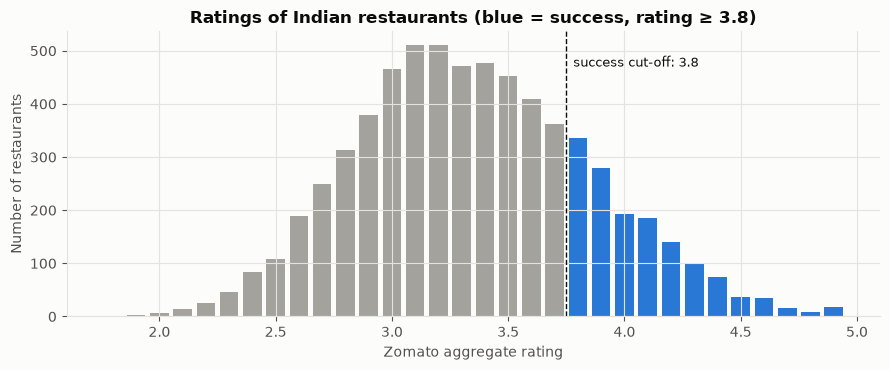

In [5]:
# Rating histogram, with the bars at or above the 3.8 cut-off coloured as "success".
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.round(np.arange(1.75, 5.0, 0.1), 2)  # one bar per 0.1 rating step (ratings have 1 decimal)
counts, edges = np.histogram(rated["Aggregate rating"], bins=bins)
centers = (edges[:-1] + edges[1:]) / 2
colors = [BLUE if c >= P.SUCCESS_RATING else NEUTRAL for c in centers]
ax.bar(centers, counts, width=0.08, color=colors)
ax.axvline(P.SUCCESS_RATING - 0.05, color=INK, linestyle="--", linewidth=1)
ax.text(P.SUCCESS_RATING - 0.02, counts.max() * 0.92, "success cut-off: 3.8", color=INK, fontsize=9)
ax.set_xlabel("Zomato aggregate rating")
ax.set_ylabel("Number of restaurants")
ax.set_title("Ratings of Indian restaurants (blue = success, rating ≥ 3.8)")
finish(fig, "01_rating_histogram")

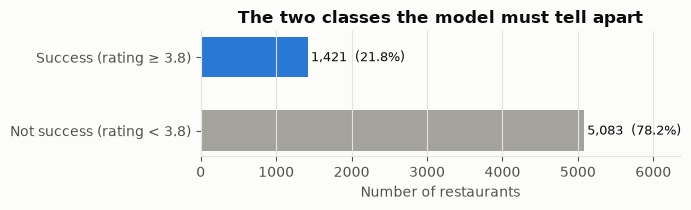

In [6]:
# Class balance: how many restaurants are in each class.
class_counts = rated["success"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 2.2))
labels = ["Not success (rating < 3.8)", "Success (rating ≥ 3.8)"]
ax.barh(labels, class_counts.values, color=[NEUTRAL, BLUE], height=0.55)
for i, n in enumerate(class_counts.values):
    ax.text(n + 40, i, f"{n:,}  ({n / len(rated):.1%})", va="center", color=INK, fontsize=9)
ax.set_xlim(0, class_counts.max() * 1.25)
ax.set_xlabel("Number of restaurants")
ax.set_title("The two classes the model must tell apart")
ax.grid(axis="y", visible=False)
finish(fig, "02_class_balance")

The classes are **imbalanced** (about 1 success for every 3.6 non-successes). That matters later: accuracy alone
would be misleading (predicting "not success" for everyone is already 78% accurate), so we judge the models with
log loss, ROC-AUC and precision–recall, and choose the threshold from business costs instead of using 0.5.

Next, the **price hypothesis** in the raw data: the share of successful restaurants at each price level, separately
for restaurants that deliver online and those that don't.

rate             n       
Has Online delivery    No   Yes      No    Yes
price_band                                    
≤300                 0.09  0.15  1174.0  265.0
300–500              0.10  0.15  1182.0  719.0
500–800              0.18  0.21   824.0  812.0
800–1k               0.38  0.35   228.0  203.0
1k–1.5k              0.57  0.43   362.0  206.0
1.5k–2k              0.54  0.70   206.0  105.0
2k–3k                0.37  0.41   125.0   17.0
>3k                  0.51   NaN    76.0    NaN

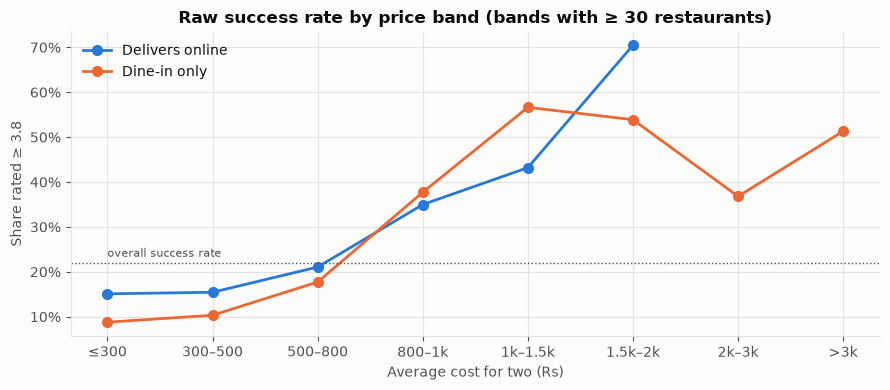

In [7]:
# Price bands (Rs, cost for two). Bands with fewer than 30 restaurants are hidden
# because a success rate computed from a handful of restaurants is mostly noise.
price_bins = [0, 300, 500, 800, 1000, 1500, 2000, 3000, 10_000]
price_labels = ["≤300", "300–500", "500–800", "800–1k", "1k–1.5k", "1.5k–2k", "2k–3k", ">3k"]
rated["price_band"] = pd.cut(rated["Average Cost for two"], price_bins, labels=price_labels)
band_stats = (rated.groupby(["price_band", "Has Online delivery"], observed=True)["success"]
              .agg(rate="mean", n="size").reset_index())
display(band_stats.pivot(index="price_band", columns="Has Online delivery", values=["rate", "n"]).round(2))

fig, ax = plt.subplots(figsize=(9, 4))
for color, (flag, label) in zip([BLUE, ORANGE], [("Yes", "Delivers online"), ("No", "Dine-in only")]):
    s = band_stats[(band_stats["Has Online delivery"] == flag) & (band_stats["n"] >= 30)]
    ax.plot(s["price_band"].astype(str), s["rate"], marker="o", markersize=7, color=color, label=label)
ax.axhline(rated["success"].mean(), color=INK_2, linestyle=":", linewidth=1)
ax.text(0, rated["success"].mean() + 0.015, "overall success rate", color=INK_2, fontsize=8)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Average cost for two (Rs)")
ax.set_ylabel("Share rated ≥ 3.8")
ax.set_title("Raw success rate by price band (bands with ≥ 30 restaurants)")
ax.legend(loc="upper left")
finish(fig, "03_success_by_price")

Raw pattern (to be checked by the model, which can separate price from cuisine, city and dine-in effects): success
rises with price up to roughly Rs 1,500–2,000 and then falls for Rs 2,000–3,000. Cheap restaurants rarely reach
3.8. Delivery restaurants are concentrated below Rs 1,500 — the price range that matters for a cloud kitchen.

Now **cuisines** and **cities**.

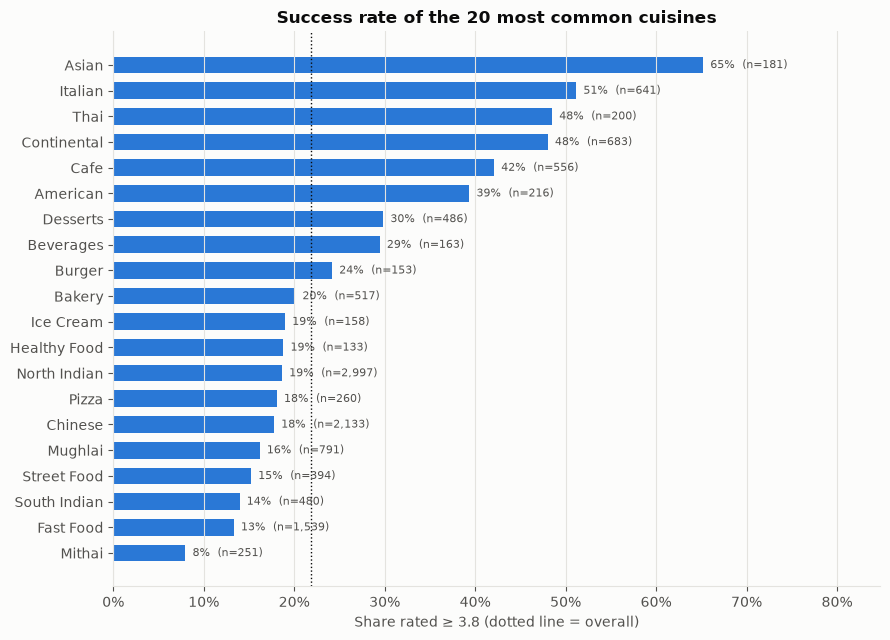

In [8]:
# Success rate per cuisine, for the 20 most common cuisines. A restaurant that lists
# several cuisines counts once for each of them.
by_cuisine = (rated.assign(cuisine=rated["Cuisines"].map(P.split_cuisines)).explode("cuisine")
              .groupby("cuisine")["success"].agg(rate="mean", n="size"))
top = by_cuisine.sort_values("n", ascending=False).head(20).sort_values("rate")

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top["rate"], color=BLUE, height=0.65)
for i, (rate, n) in enumerate(zip(top["rate"], top["n"])):
    ax.text(rate + 0.008, i, f"{rate:.0%}  (n={n:,})", va="center", fontsize=8, color=INK_2)
ax.axvline(rated["success"].mean(), color=INK, linestyle=":", linewidth=1)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlim(0, top["rate"].max() * 1.3)
ax.set_xlabel("Share rated ≥ 3.8 (dotted line = overall)")
ax.set_title("Success rate of the 20 most common cuisines")
ax.grid(axis="y", visible=False)
finish(fig, "04_success_by_cuisine")

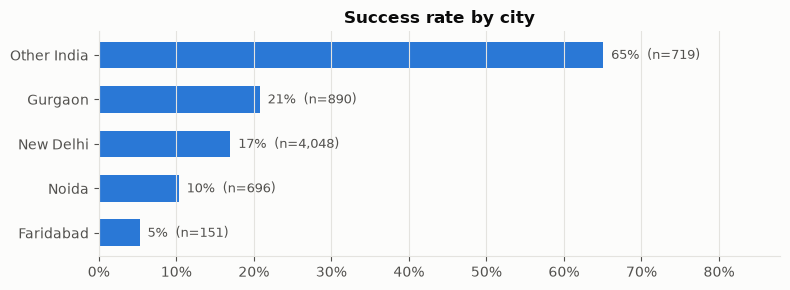

In [9]:
# Success rate per city group (the same grouping the model uses).
by_city = (rated.assign(city=rated["City"].map(P.city_group))
           .groupby("city")["success"].agg(rate="mean", n="size").sort_values("rate"))
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(by_city.index, by_city["rate"], color=BLUE, height=0.6)
for i, (rate, n) in enumerate(zip(by_city["rate"], by_city["n"])):
    ax.text(rate + 0.01, i, f"{rate:.0%}  (n={n:,})", va="center", fontsize=9, color=INK_2)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlim(0, by_city["rate"].max() * 1.35)
ax.set_title("Success rate by city")
ax.grid(axis="y", visible=False)
finish(fig, "05_success_by_city")

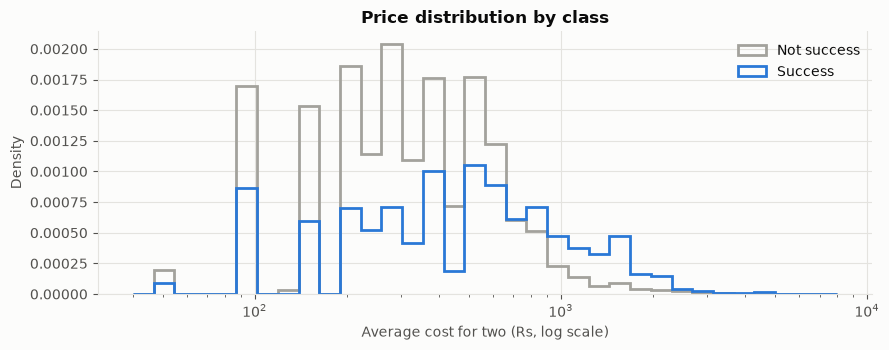

In [10]:
# Price distribution of each class, on a log scale (prices range from Rs 50 to Rs 8,000).
# density=True puts both classes on the same vertical scale even though one class is
# 3.6x bigger - so we compare SHAPES, not sizes.
fig, ax = plt.subplots(figsize=(9, 3.6))
log_bins = np.logspace(np.log10(40), np.log10(8000), 35)
for flag, color, label in [(0, NEUTRAL, "Not success"), (1, BLUE, "Success")]:
    ax.hist(rated.loc[rated["success"] == flag, "Average Cost for two"], bins=log_bins,
            density=True, histtype="step", linewidth=2, color=color, label=label)
ax.set_xscale("log")
ax.set_xlabel("Average cost for two (Rs, log scale)")
ax.set_ylabel("Density")
ax.set_title("Price distribution by class")
ax.legend()
finish(fig, "06_price_by_class")

## 3. Train / validation / test split

**Decision: keep all outlets of a chain in the same split.** Domino's has 79 rows, Cafe Coffee Day 83. With a purely
random split, the model would learn from some Domino's outlets and be "tested" on other Domino's outlets with
nearly identical inputs — an easy shortcut that makes the test score look better than it really is. Our real use
case is a **new brand** the model has never seen, so the test set should contain only brands that never appear in
training.

**How:** `StratifiedGroupKFold` with 7 folds. *Group* = brand (normalised restaurant name), so a brand never sits
in two folds. *Stratified* = each fold keeps roughly the same share of successes. One fold (≈14%) becomes the test
set, one (≈14%) the validation set, and the remaining five (≈71%) the training set.

There is **no time column** in this dataset, so a time-based split isn't possible. Ratings are a snapshot taken at
one moment, so a grouped split is the main protection against leakage here.

- **Train**: models learn their weights from it; every feature statistic is computed from it.
- **Validation**: used to choose the regularisation strength, learning rate and decision threshold.
- **Test**: touched once, at the end, for the final honest score.

In [11]:
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = list(splitter.split(rated, y=rated["success"], groups=rated["brand"]))
test_idx = folds[0][1]
val_idx = folds[1][1]
train_idx = np.setdiff1d(np.arange(len(rated)), np.concatenate([test_idx, val_idx]))

train_df, val_df, test_df = rated.iloc[train_idx], rated.iloc[val_idx], rated.iloc[test_idx]

# Check 1: no brand appears in more than one split.
assert not set(train_df["brand"]) & set(val_df["brand"])
assert not set(train_df["brand"]) & set(test_df["brand"])
assert not set(val_df["brand"]) & set(test_df["brand"])

# Check 2: sizes and success rates are similar across splits.
split_summary = pd.DataFrame({
    "restaurants": [len(train_df), len(val_df), len(test_df)],
    "share of data": [len(train_df) / len(rated), len(val_df) / len(rated), len(test_df) / len(rated)],
    "success rate": [train_df["success"].mean(), val_df["success"].mean(), test_df["success"].mean()],
    "brands": [train_df["brand"].nunique(), val_df["brand"].nunique(), test_df["brand"].nunique()],
}, index=["train", "validation", "test"])
display(split_summary.round(3))

,restaurants,share of data,success rate,brands
train,4648,0.715,0.218,3476
validation,928,0.143,0.219,686
test,928,0.143,0.219,697


## 4. Feature engineering

All the logic is in `pipeline.build_features` (fully commented there). Summary:

| Group | Feature(s) | Why |
|---|---|---|
| **Price (hypothesis)** | `log_cost` | Base price level. Log scale: doubling the price counts the same at any level. |
| | `rel_price`, `rel_price_sq` | Price ÷ typical price of the cuisines served (average over all listed cuisines). The square lets the model draw a hill, i.e. a **sweet spot**. Clipped to the 1st–99th percentile so extreme values don't dominate the square. |
| | `log_cost_x_delivery` | Lets price matter **differently for delivery restaurants**. |
| **Services** | `has_delivery`, `has_table_booking` | Delivery = cloud-kitchen setting. Table booking soaks up the "nice dining room" effect so it isn't wrongly credited to price. |
| **Brand** | `is_chain` | Brand has more than one outlet in India. |
| **Cuisine** | `n_cuisines`, `cuisine_<name>` (≥ 50 training restaurants), `cuisine_Other` | Which cuisines tend to succeed; focused vs. sprawling menus. Rare cuisines pooled to avoid weights learned from a handful of examples. |
| **Location** | `log_locality_restaurants`, `log_locality_median_cost`, `city_*` | Competition, upmarket vs. budget area, and city-level rating culture (New Delhi = reference city). |

**Leakage rule:** every typical price (per cuisine, per locality, per city) is computed from the **training split
only**, then applied unchanged to validation, test and the app. Two market counts (restaurants per locality,
outlets per brand) use every Indian listing, since they contain no rating information and describe what a company
can see before launching. With chains kept together, counting outlets from the training split alone would make
every test chain look like it has zero outlets.

In [12]:
# Learn the feature statistics from the TRAINING split only ...
feature_params = P.fit_feature_params(train_df, india)
FEATURES = feature_params["feature_names"]

# ... and apply the same statistics to every split.
X_train_raw = P.build_features(train_df, feature_params)
X_val_raw = P.build_features(val_df, feature_params)
X_test_raw = P.build_features(test_df, feature_params)
y_train = train_df["success"].to_numpy()
y_val = val_df["success"].to_numpy()
y_test = test_df["success"].to_numpy()

print(f"{len(FEATURES)} features:", ", ".join(FEATURES))
print(f"\nCuisines with their own column ({len(feature_params['common_cuisines'])}):",
      ", ".join(feature_params["common_cuisines"]))
print("Relative price clipped to:", np.round(feature_params["rel_price_clip"], 2))
display(X_train_raw.head(5).T.round(3))

42 features: log_cost, rel_price, rel_price_sq, log_cost_x_delivery, has_delivery, has_table_booking, is_chain, n_cuisines, cuisine_American, cuisine_Asian, cuisine_Bakery, cuisine_Beverages, cuisine_Biryani, cuisine_Burger, cuisine_Cafe, cuisine_Chinese, cuisine_Continental, cuisine_Desserts, cuisine_European, cuisine_Fast_Food, cuisine_Finger_Food, cuisine_Ice_Cream, cuisine_Italian, cuisine_Japanese, cuisine_Mediterranean, cuisine_Mexican, cuisine_Mithai, cuisine_Mughlai, cuisine_North_Indian, cuisine_Pizza, cuisine_Raw_Meats, cuisine_Seafood, cuisine_South_Indian, cuisine_Street_Food, cuisine_Thai, cuisine_Other, log_locality_restaurants, log_locality_median_cost, city_Gurgaon, city_Noida, city_Faridabad, city_Other_India

Cuisines with their own column (27): American, Asian, Bakery, Beverages, Biryani, Burger, Cafe, Chinese, Continental, Desserts, European, Fast Food, Finger Food, Ice Cream, Italian, Japanese, Mediterranean, Mexican, Mithai, Mughlai, North Indian, Pizza, Raw Meats

,0,1,3,4,6
log_cost,6.745,6.551,5.991,6.908,7.824
rel_price,1.360,1.120,0.571,1.622,3.714
rel_price_sq,1.850,1.254,0.327,2.630,13.794
log_cost_x_delivery,0.000,0.000,0.000,0.000,0.000
has_delivery,0.000,0.000,0.000,0.000,0.000
has_table_booking,0.000,0.000,0.000,0.000,0.000
is_chain,0.000,0.000,0.000,0.000,0.000
n_cuisines,2.000,2.000,1.000,3.000,2.000
cuisine_American,0.000,0.000,0.000,0.000,0.000
cuisine_Asian,0.000,0.000,0.000,0.000,0.000


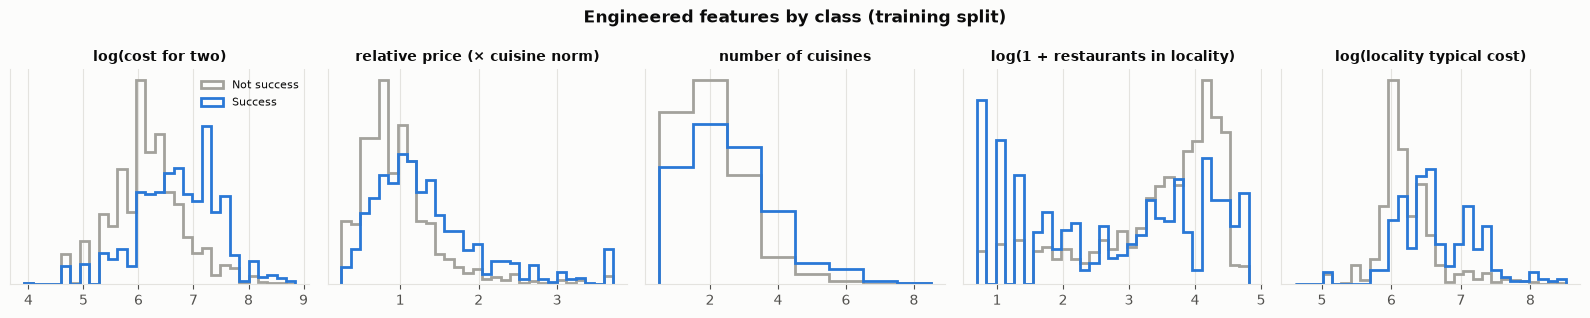

In [13]:
# Distributions of the engineered numeric features, split by class. If the two
# outlines differ, the feature carries information about success.
numeric = ["log_cost", "rel_price", "n_cuisines", "log_locality_restaurants", "log_locality_median_cost"]
titles = ["log(cost for two)", "relative price (× cuisine norm)", "number of cuisines",
          "log(1 + restaurants in locality)", "log(locality typical cost)"]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, col, title in zip(axes, numeric, titles):
    lo, hi = X_train_raw[col].min(), X_train_raw[col].max()
    bins = np.arange(0.5, hi + 1.5, 1) if col == "n_cuisines" else np.linspace(lo, hi, 30)
    for flag, color, label in [(0, NEUTRAL, "Not success"), (1, BLUE, "Success")]:
        ax.hist(X_train_raw.loc[y_train == flag, col], bins=bins, density=True,
                histtype="step", linewidth=2, color=color, label=label)
    ax.set_title(title, fontsize=10)
    ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle("Engineered features by class (training split)", fontweight="bold")
finish(fig, "07_feature_distributions")

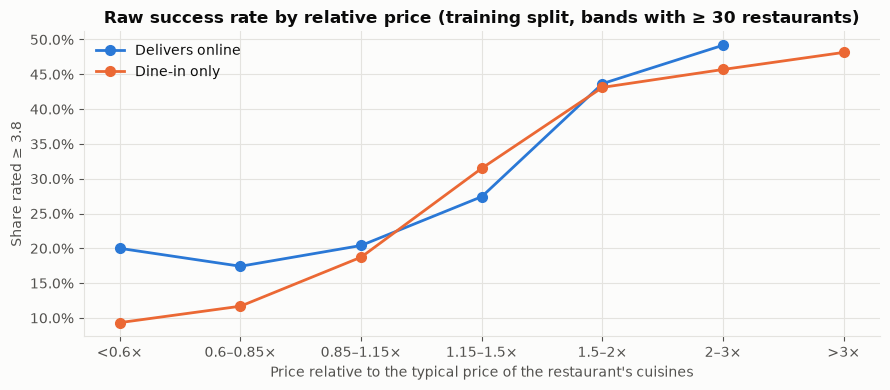

In [14]:
# The hypothesis feature on its own: raw success rate by relative-price band
# (training split), for delivery vs. dine-in restaurants.
rel_bins = [0, 0.6, 0.85, 1.15, 1.5, 2.0, 3.0, 100]
rel_labels = ["<0.6×", "0.6–0.85×", "0.85–1.15×", "1.15–1.5×", "1.5–2×", "2–3×", ">3×"]
tmp = pd.DataFrame({"band": pd.cut(X_train_raw["rel_price"], rel_bins, labels=rel_labels),
                    "delivery": X_train_raw["has_delivery"].map({1.0: "Delivers online", 0.0: "Dine-in only"}),
                    "success": y_train})
rel_stats = tmp.groupby(["band", "delivery"], observed=True)["success"].agg(rate="mean", n="size").reset_index()

fig, ax = plt.subplots(figsize=(9, 4))
for color, label in zip([BLUE, ORANGE], ["Delivers online", "Dine-in only"]):
    s = rel_stats[(rel_stats["delivery"] == label) & (rel_stats["n"] >= 30)]
    ax.plot(s["band"].astype(str), s["rate"], marker="o", markersize=7, color=color, label=label)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Price relative to the typical price of the restaurant's cuisines")
ax.set_ylabel("Share rated ≥ 3.8")
ax.set_title("Raw success rate by relative price (training split, bands with ≥ 30 restaurants)")
ax.legend(loc="upper left")
finish(fig, "08_success_by_relative_price")

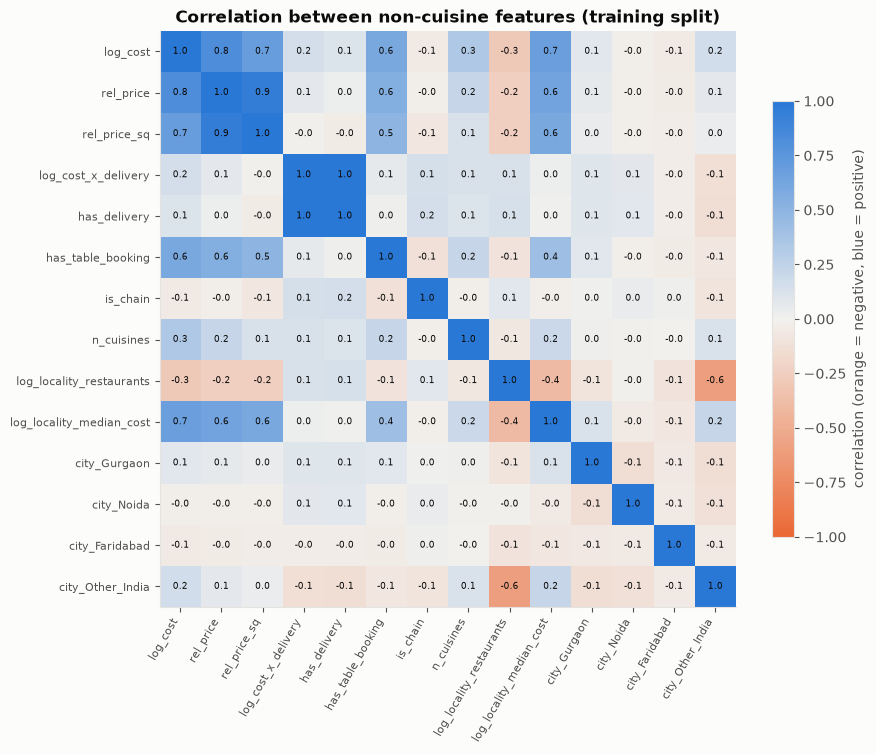

In [15]:
# Correlations between the non-cuisine features. Strong correlations (close to
# +1 or -1) mean two features carry overlapping information. That is expected
# here (rel_price vs. rel_price_sq, log_cost vs. log_cost_x_delivery) and is
# one reason we use L2 regularisation: it keeps the weights of correlated
# features stable instead of letting them blow up in opposite directions.
corr_cols = [c for c in FEATURES if not c.startswith("cuisine_")]
corr = X_train_raw[corr_cols].corr()
diverging = matplotlib.colors.LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f1ee", BLUE])
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6.5, color=INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="correlation (orange = negative, blue = positive)")
ax.set_title("Correlation between non-cuisine features (training split)")
finish(fig, "09_feature_correlations")

### Scaling

Every feature is **standardised** (mean 0, standard deviation 1) with statistics from the training split.

- **Gradient descent needs it.** Without scaling, `log_locality_median_cost` (≈ 6) and a 0/1 cuisine flag would get
  very different gradient sizes. One learning rate would then be too big for some weights and too small for
  others, and training would crawl or diverge.
- **Regularisation needs it.** The L2 penalty shrinks all weights equally, which is only fair if the features are on
  the same scale.
- **Comparability.** All three methods receive exactly the same scaled numbers, so any difference between them
  comes from the training method, not the data.

In [16]:
scaler = StandardScaler().fit(X_train_raw)          # learns mean and std from TRAIN only
X_train = scaler.transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)
print("Train means after scaling (should be ~0):", np.round(X_train.mean(axis=0)[:5], 6))
print("Train stds  after scaling (should be ~1):", np.round(X_train.std(axis=0)[:5], 6))

# PyTorch versions of the same arrays. float32 is PyTorch's standard training dtype.
Xt_train = torch.tensor(X_train, dtype=torch.float32)
Xt_val = torch.tensor(X_val, dtype=torch.float32)
Xt_test = torch.tensor(X_test, dtype=torch.float32)
yt_train = torch.tensor(y_train, dtype=torch.float32)
yt_val = torch.tensor(y_val, dtype=torch.float32)

Train means after scaling (should be ~0): [-0. -0. -0. -0. -0.]
Train stds  after scaling (should be ~1): [1. 1. 1. 1. 1.]


## 5. Models

### 5.0 Evaluation metrics and the naive baseline

| Metric | What it measures | Better |
|---|---|---|
| **Log loss** (binary cross-entropy) | How good the predicted *probabilities* are. It is also the loss all three methods minimise. | lower |
| **ROC-AUC** | Chance that a random success gets a higher score than a random non-success. 0.5 = guessing. | higher |
| **Average precision** (PR-AUC) | Precision averaged over all recall levels. Suits imbalanced data; random guessing scores the success rate (~0.22). | higher |
| **Brier score** | Mean squared error of the probabilities. | lower |

**Naive baseline:** give every restaurant the same probability, the training success rate (~22%). It knows how
common success is but nothing about any individual restaurant. Every model must beat it.

In [17]:
def evaluate(y_true, prob):
    """The four probability metrics for one set of predictions."""
    return {
        "log loss": log_loss(y_true, prob, labels=[0, 1]),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "avg precision": average_precision_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
    }


base_rate = y_train.mean()
baseline_val = np.full(len(y_val), base_rate)
baseline_test = np.full(len(y_test), base_rate)
print(f"Baseline predicts p = {base_rate:.3f} for every restaurant.")
display(pd.DataFrame({"validation": evaluate(y_val, baseline_val),
                      "test": evaluate(y_test, baseline_test)}).round(4))

Baseline predicts p = 0.218 for every restaurant.


,validation,test
log loss,0.5253,0.5253
ROC-AUC,0.5000,0.5000
avg precision,0.2188,0.2188
Brier,0.1709,0.1709


### The objective all three methods minimise

To compare the three methods fairly, they must minimise **exactly the same function**. scikit-learn's
`LogisticRegression` minimises

$$\tfrac{1}{2}\lVert w\rVert^2 + C \sum_i \text{BCE}_i$$

where $C$ is the **inverse** regularisation strength (smaller $C$ = stronger penalty) and the bias is not penalised.
Dividing by $C \cdot n$ (which doesn't change where the minimum is) gives the "mean loss + penalty" form we use in
PyTorch:

$$\underbrace{\tfrac{1}{n}\sum_i \text{BCE}_i}_{\text{mean binary cross-entropy}} \;+\; \frac{\lambda}{2}\lVert w\rVert^2,\qquad \lambda = \frac{1}{C\,n}$$

The penalty applies to the weights only, not the bias. We **don't** use PyTorch's `weight_decay` option: it would
also shrink the bias, so it would be a slightly different objective from scikit-learn's.

### 5.1 scikit-learn — tuning the regularisation strength $C$

We try six values of $C$ on a log scale, train on the training split, and keep the one with the lowest
**validation log loss**. Too small a $C$ squashes all weights towards 0 (underfitting); too large a $C$ barely
penalises them (risk of overfitting).

,C,lambda = 1/(C·n),train log loss,val log loss,val ROC-AUC
0,0.001,0.21515,0.40691,0.40903,0.83444
1,0.010,0.02151,0.38084,0.38365,0.84075
2,0.100,0.00215,0.37770,0.38273,0.83985
3,1.000,0.00022,0.37747,0.38385,0.83849
4,10.000,0.00002,0.37745,0.38410,0.83838
5,100.000,0.00000,0.37745,0.38413,0.83834


Chosen C = 0.1  ->  lambda = 0.002151


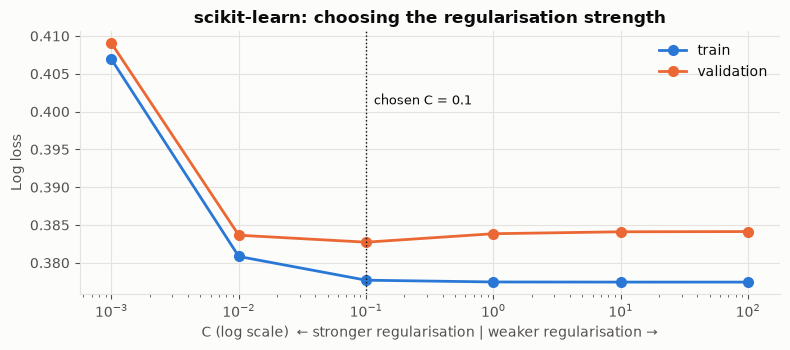

In [18]:
C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
rows = []
for C in C_GRID:
    # lbfgs = a second-order-style optimiser; with a tiny tolerance it reaches the exact minimum,
    # which gives us a precise target for the two PyTorch versions to match.
    m = LogisticRegression(C=C, solver="lbfgs", max_iter=10_000, tol=1e-10)
    m.fit(X_train, y_train)
    rows.append({"C": C, "lambda = 1/(C·n)": 1 / (C * len(y_train)),
                 "train log loss": log_loss(y_train, m.predict_proba(X_train)[:, 1]),
                 "val log loss": log_loss(y_val, m.predict_proba(X_val)[:, 1]),
                 "val ROC-AUC": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])})
c_table = pd.DataFrame(rows)
display(c_table.round(5))

BEST_C = float(c_table.loc[c_table["val log loss"].idxmin(), "C"])
LAMBDA = 1.0 / (BEST_C * len(y_train))     # the same penalty, in PyTorch form
print(f"Chosen C = {BEST_C}  ->  lambda = {LAMBDA:.6f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(c_table["C"], c_table["train log loss"], marker="o", markersize=7, color=BLUE, label="train")
ax.plot(c_table["C"], c_table["val log loss"], marker="o", markersize=7, color=ORANGE, label="validation")
ax.axvline(BEST_C, color=INK, linestyle=":", linewidth=1)
ax.text(BEST_C * 1.15, ax.get_ylim()[1] * 0.98, f"chosen C = {BEST_C}", fontsize=9, va="top")
ax.set_xscale("log")
ax.set_xlabel("C (log scale)  ← stronger regularisation | weaker regularisation →")
ax.set_ylabel("Log loss")
ax.set_title("scikit-learn: choosing the regularisation strength")
ax.legend()
finish(fig, "10_sklearn_C_tuning")

In [19]:
# Final scikit-learn model with the chosen C, trained on the training split.
sk_model = LogisticRegression(C=BEST_C, solver="lbfgs", max_iter=10_000, tol=1e-10).fit(X_train, y_train)
p_val_sk = sk_model.predict_proba(X_val)[:, 1]
p_test_sk = sk_model.predict_proba(X_test)[:, 1]

# The value of the objective at sklearn's optimum. The PyTorch loops should approach this number.
def objective_np(w, b, X, y, lam):
    p = 1 / (1 + np.exp(-(X @ w + b)))
    return log_loss(y, p) + lam / 2 * np.sum(w ** 2)

SK_OBJECTIVE = objective_np(sk_model.coef_[0], sk_model.intercept_[0], X_train, y_train, LAMBDA)
print(f"scikit-learn objective on train (mean BCE + L2): {SK_OBJECTIVE:.6f}")

scikit-learn objective on train (mean BCE + L2): 0.379474


### 5.2 Manual PyTorch loop (as in the Session 5 notebook)

Raw tensors `w` and `b` with `requires_grad=True`, a hand-written sigmoid + binary cross-entropy + L2 penalty,
`loss.backward()` for the gradients, and a **manual gradient-descent step** inside `torch.no_grad()`, followed by
`.grad.zero_()` (otherwise gradients would accumulate across epochs). Every epoch uses the **whole training set**
(full-batch gradient descent), the same as in class.

**Tuning the learning rate.** The learning rate is the step size. Too small and training crawls; too large and each
step overshoots the minimum, so the loss bounces around or explodes. We train with five learning rates for the same
number of epochs and plot the **training objective** (mean BCE + L2) per epoch. The dashed line is scikit-learn's
optimum, the lowest value possible for this objective.

In [20]:
def bce_loss(prob, y):
    """Binary cross-entropy, written by hand: -[y·log(p) + (1-y)·log(1-p)], averaged.
    Probabilities are clamped away from exactly 0 and 1 so we never take log(0) = -infinity."""
    prob = prob.clamp(1e-7, 1 - 1e-7)
    return -(y * torch.log(prob) + (1 - y) * torch.log(1 - prob)).mean()


def train_manual(X, y, lr, n_epochs, lam, X_val=None, y_val=None):
    """Full-batch gradient descent on the regularised logistic-regression objective.
    Returns the learned w, b and the per-epoch history of train objective / validation BCE."""
    n_features = X.shape[1]
    # Start from all-zero weights: every restaurant starts at p = sigmoid(0) = 0.5.
    w = torch.zeros(n_features, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    history = {"train_objective": [], "val_bce": []}

    for epoch in range(n_epochs):
        # 1) Forward pass: linear score z = X @ w + b, squashed into a probability by the sigmoid.
        prob = torch.sigmoid(X @ w + b)
        # 2) Loss = mean BCE + L2 penalty on the weights (not on the bias).
        loss = bce_loss(prob, y) + lam / 2 * (w ** 2).sum()
        # 3) Backward pass: autograd fills w.grad and b.grad with d(loss)/dw and d(loss)/db.
        loss.backward()
        # 4) Update: step against the gradient. no_grad() stops autograd from recording the update itself.
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        # 5) Reset gradients - .backward() ADDS to .grad, so without this they would pile up epoch after epoch.
        w.grad.zero_()
        b.grad.zero_()

        history["train_objective"].append(loss.item())
        if X_val is not None:
            with torch.no_grad():
                history["val_bce"].append(bce_loss(torch.sigmoid(X_val @ w + b), y_val).item())
    return w.detach(), b.detach(), history


MANUAL_LR_GRID = [0.01, 0.1, 1.0, 3.0, 10.0]
# One epoch budget for every PyTorch run (learning-rate sweeps AND final models), so the final
# model is trained under exactly the conditions its learning rate was chosen under.
SWEEP_EPOCHS = 3000
manual_sweep, manual_sweep_val = {}, {}
for lr in MANUAL_LR_GRID:
    _, _, hist = train_manual(Xt_train, yt_train, lr, SWEEP_EPOCHS, LAMBDA, Xt_val, yt_val)
    manual_sweep[lr] = hist["train_objective"]
    manual_sweep_val[lr] = hist["val_bce"]

manual_lr_table = pd.DataFrame({
    "learning rate": MANUAL_LR_GRID,
    "final train objective": [manual_sweep[lr][-1] for lr in MANUAL_LR_GRID],
    "gap to sklearn optimum": [manual_sweep[lr][-1] - SK_OBJECTIVE for lr in MANUAL_LR_GRID],
    "final validation BCE": [manual_sweep_val[lr][-1] for lr in MANUAL_LR_GRID],
})
display(manual_lr_table.round(6))

,learning rate,final train objective,gap to sklearn optimum,final validation BCE
0,0.01,0.381577,0.002103,0.384154
1,0.10,0.379494,0.000019,0.382471
2,1.00,0.379474,0.000000,0.382728
3,3.00,0.395813,0.016339,0.397176
4,10.00,1.751491,1.372017,0.696079


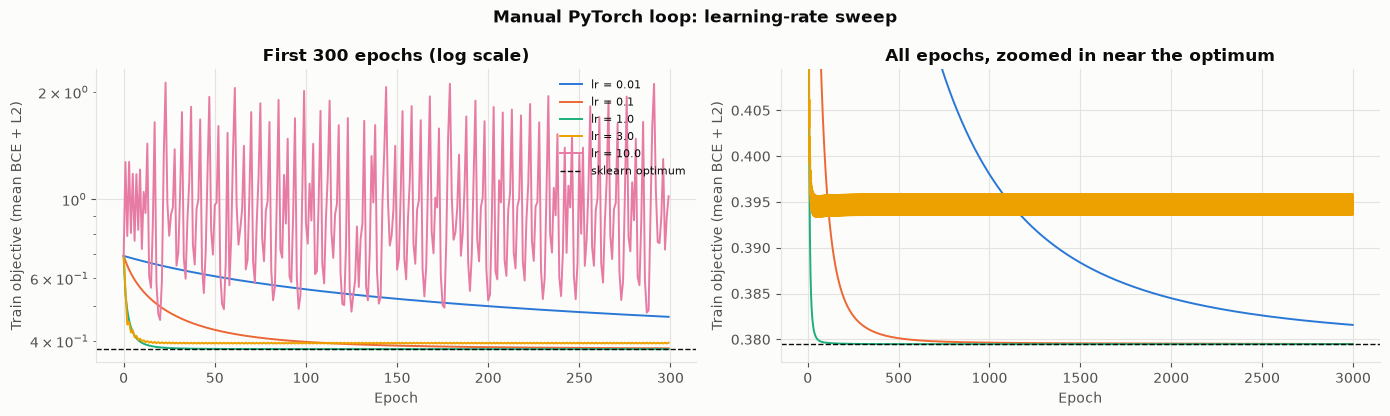

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
# Left: the first 300 epochs on a log scale, where you can see each learning rate's behaviour
# (lr = 10 jumps around wildly instead of going down). Right: all epochs, zoomed in near the optimum.
for ax, ylim, n_show, title in [(axes[0], None, 300, "First 300 epochs (log scale)"),
                                (axes[1], (SK_OBJECTIVE - 0.002, SK_OBJECTIVE + 0.03), SWEEP_EPOCHS,
                                 "All epochs, zoomed in near the optimum")]:
    for color, lr in zip(SERIES, MANUAL_LR_GRID):
        ax.plot(manual_sweep[lr][:n_show], color=color, linewidth=1.4, label=f"lr = {lr}")
    ax.axhline(SK_OBJECTIVE, color=INK, linestyle="--", linewidth=1, label="sklearn optimum")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Train objective (mean BCE + L2)")
    ax.set_title(title)
    if ylim:
        ax.set_ylim(*ylim)
    else:
        ax.set_yscale("log")
axes[0].legend(fontsize=8)
fig.suptitle("Manual PyTorch loop: learning-rate sweep", fontweight="bold")
finish(fig, "11_manual_lr_sweep")

How to read this chart: a **small** learning rate decreases smoothly but is still far from the optimum after 3,000
epochs. A **too-large** one overshoots: the loss either stalls above the optimum (bouncing back and forth across
the minimum) or explodes. We pick the learning rate with the lowest **validation** loss (BCE) after 3,000
epochs. Like every tuning choice, it is made on the validation split, never the test split. The regularisation
strength is **not** re-tuned here: $\lambda$ was chosen in 5.1 and is the same for all three methods.

Chosen learning rate: 0.1, training for 3000 epochs


Final train objective: 0.379494  (sklearn: 0.379474)


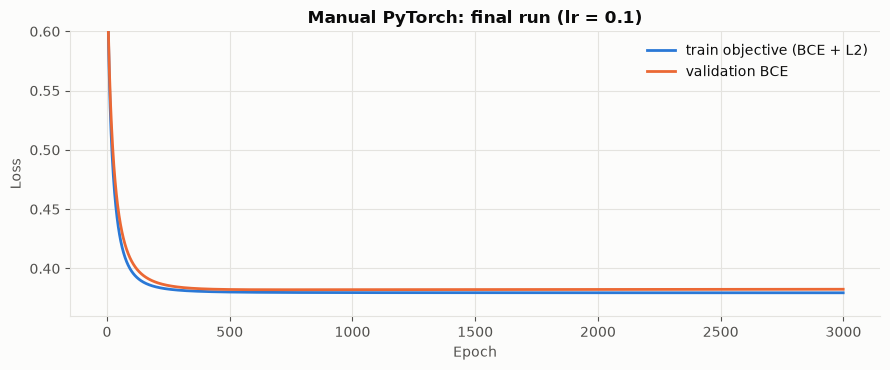

In [22]:
# Choose the learning rate with the lowest final VALIDATION loss (diverged runs give NaN/huge values, never chosen).
finite = manual_lr_table.dropna()
MANUAL_LR = float(finite.loc[finite["final validation BCE"].idxmin(), "learning rate"])
MANUAL_EPOCHS = SWEEP_EPOCHS
print(f"Chosen learning rate: {MANUAL_LR}, training for {MANUAL_EPOCHS} epochs")

manual_w, manual_b, manual_hist = train_manual(Xt_train, yt_train, MANUAL_LR, MANUAL_EPOCHS, LAMBDA, Xt_val, yt_val)
with torch.no_grad():
    p_val_manual = torch.sigmoid(Xt_val @ manual_w + manual_b).numpy()
    p_test_manual = torch.sigmoid(Xt_test @ manual_w + manual_b).numpy()
print(f"Final train objective: {manual_hist['train_objective'][-1]:.6f}  (sklearn: {SK_OBJECTIVE:.6f})")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(manual_hist["train_objective"], color=BLUE, label="train objective (BCE + L2)")
ax.plot(manual_hist["val_bce"], color=ORANGE, label="validation BCE")
ax.set_ylim(min(manual_hist["train_objective"]) - 0.02, 0.6)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title(f"Manual PyTorch: final run (lr = {MANUAL_LR})")
ax.legend()
finish(fig, "12_manual_final_curve")

If the validation curve flattens at roughly the same level as the training curve, the model isn't overfitting. With
~42 weights and ~4,600 training restaurants, overfitting risk is low, which also explains why the choice of $C$
in 5.1 made little difference.

### 5.3 Standard PyTorch workflow (`nn.Module` + `torch.optim`)

The same model written the "everyday" way:

- **`LogisticRegressionModel`** (in `pipeline.py`): an `nn.Module` holding one `nn.Linear(n_features, 1)`. It
  replaces our raw `w` and `b`, and initialises them with small **random** values (not zeros).
- **`nn.BCEWithLogitsLoss`**: the model outputs raw scores (logits), and this loss applies the sigmoid and the
  binary cross-entropy in one numerically stable step. It never computes `log(0)`, so no clamping is needed.
- **Optimiser: `torch.optim.Adam`**. Plain gradient descent uses one step size for every weight. Adam keeps two
  running averages per weight: the average gradient (*momentum*, which smooths the direction) and the average
  squared gradient (which scales each weight's step, so weights with large gradients take smaller steps).
  `optimizer.zero_grad()` replaces the manual `.grad.zero_()`, and `optimizer.step()` replaces the manual
  `torch.no_grad()` update.
- **Why Adam and not AdamW?** AdamW applies "decoupled weight decay": it shrinks the weights directly in the update
  step, outside the loss, and by default shrinks the bias too. That is a *different* regularisation from
  scikit-learn's L2 penalty inside the loss, so the three methods would no longer minimise the same objective and
  couldn't be expected to match. With Adam, the L2 penalty stays inside the loss, identical to 5.1 and 5.2.
- **Learning-rate schedule: `OneCycleLR`**. Instead of one fixed learning rate, the rate follows one "cycle" over
  the whole training run:
  1. **Warm-up (first 30% of epochs):** the rate rises from `max_lr / 25` up to `max_lr`. Starting small avoids
     wild first steps while Adam's running averages are still empty.
  2. **Annealing (remaining 70%):** the rate falls along a cosine curve to almost zero (`max_lr / 250,000`). Big
     steps in the middle make fast progress; tiny steps at the end let the weights settle exactly at the minimum
     instead of jittering around it.

  At the same time it cycles Adam's momentum (β₁) the opposite way, between 0.95 and 0.85: less momentum while the
  rate is high, more while it is low. The scheduler is stepped **once per epoch**, and every epoch uses the whole
  training set (full batch, as in the class notebook), so one epoch = one update.

**Tuning:** with OneCycleLR, the learning-rate hyperparameter is **`max_lr`**, the peak of the cycle. We try three
values and keep the one with the lowest **validation** loss after 3,000 epochs (the same epoch budget as the
manual loop, used for both the sweep and the final model).

In [23]:
def train_standard(X, y, max_lr, n_epochs, lam, X_val=None, y_val=None, seed=SEED):
    """Standard PyTorch training loop: Adam + OneCycleLR, full batch.
    Returns the trained model and its history (losses and the learning rate used at each epoch)."""
    torch.manual_seed(seed)                      # same random initial weights for every run
    model = LogisticRegressionModel(X.shape[1])
    loss_fn = nn.BCEWithLogitsLoss()             # sigmoid + BCE in one numerically stable step
    optimizer = torch.optim.Adam(model.parameters(), lr=max_lr)
    # OneCycleLR overrides the optimiser's learning rate every step. total_steps = n_epochs because we
    # take exactly one (full-batch) step per epoch. Defaults: 30% warm-up, cosine annealing,
    # start at max_lr/25, end at max_lr/25/10,000, and momentum (Adam's beta1) cycled 0.95 -> 0.85 -> 0.95.
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lr, total_steps=n_epochs)

    history = {"train_objective": [], "val_bce": [], "lr": []}
    for epoch in range(n_epochs):
        optimizer.zero_grad()                    # 1) clear last epoch's gradients
        logits = model(X)                        # 2) forward pass (raw scores, no sigmoid yet)
        # 3) Same objective as sklearn / the manual loop: mean BCE + lambda/2 * ||w||^2 (weights only, not bias).
        loss = loss_fn(logits, y) + lam / 2 * (model.linear.weight ** 2).sum()
        loss.backward()                          # 4) gradients for every parameter
        history["lr"].append(optimizer.param_groups[0]["lr"])   # the rate actually used for this step
        optimizer.step()                         # 5) Adam update of every parameter
        scheduler.step()                         # 6) move the learning rate along the one-cycle curve
        history["train_objective"].append(loss.item())
        if X_val is not None:
            with torch.no_grad():
                history["val_bce"].append(loss_fn(model(X_val), y_val).item())
    return model, history


LogisticRegressionModel = P.LogisticRegressionModel   # the class lives in pipeline.py (the app imports it too)

MAX_LR_GRID = [0.001, 0.01, 0.1]
standard_sweep, standard_lr_curves, rows = {}, {}, []
for max_lr in MAX_LR_GRID:
    _, hist = train_standard(Xt_train, yt_train, max_lr, SWEEP_EPOCHS, LAMBDA, Xt_val, yt_val)
    standard_sweep[max_lr] = hist["train_objective"]
    standard_lr_curves[max_lr] = hist["lr"]
    rows.append({"max_lr": max_lr,
                 "final train objective": hist["train_objective"][-1],
                 "gap to sklearn optimum": hist["train_objective"][-1] - SK_OBJECTIVE,
                 "final validation BCE": hist["val_bce"][-1]})
standard_table = pd.DataFrame(rows)
display(standard_table.round(6))

,max_lr,final train objective,gap to sklearn optimum,final validation BCE
0,0.001,0.405872,0.026397,0.420141
1,0.010,0.379474,0.000000,0.382729
2,0.100,0.379474,-0.000000,0.382728


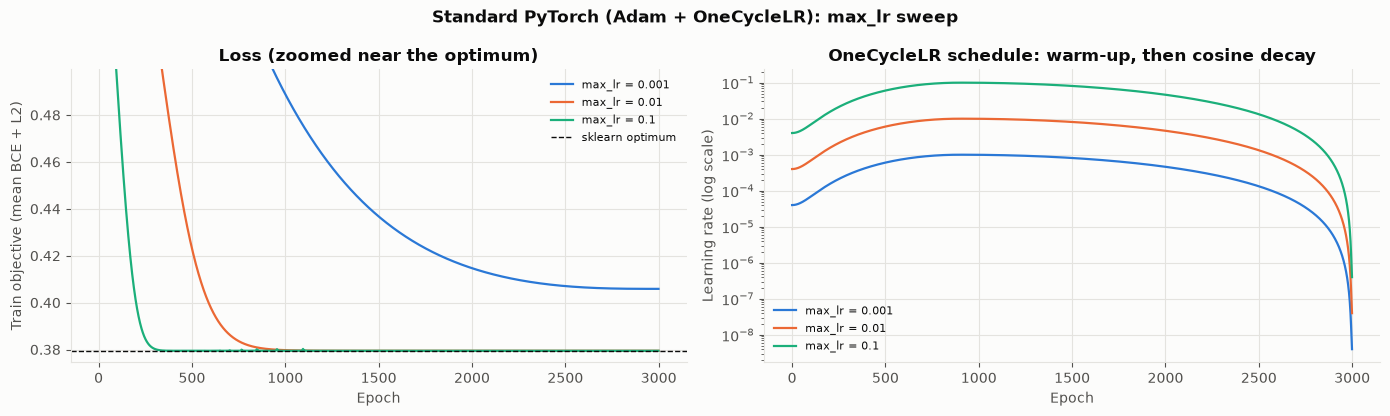

In [24]:
# Left: training objective per epoch for each max_lr. Right: the learning-rate schedule OneCycleLR produced.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for color, max_lr in zip(SERIES, MAX_LR_GRID):
    axes[0].plot(standard_sweep[max_lr], color=color, linewidth=1.6, label=f"max_lr = {max_lr}")
    axes[1].plot(standard_lr_curves[max_lr], color=color, linewidth=1.6, label=f"max_lr = {max_lr}")
axes[0].axhline(SK_OBJECTIVE, color=INK, linestyle="--", linewidth=1, label="sklearn optimum")
axes[0].set_ylim(SK_OBJECTIVE - 0.005, SK_OBJECTIVE + 0.12)
axes[0].set(xlabel="Epoch", ylabel="Train objective (mean BCE + L2)", title="Loss (zoomed near the optimum)")
axes[1].set_yscale("log")
axes[1].set(xlabel="Epoch", ylabel="Learning rate (log scale)", title="OneCycleLR schedule: warm-up, then cosine decay")
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle("Standard PyTorch (Adam + OneCycleLR): max_lr sweep", fontweight="bold")
finish(fig, "13_standard_optimizer_sweep")

Chosen: Adam + OneCycleLR with max_lr = 0.1, training for 3000 epochs


Final train objective: 0.379474  (sklearn: 0.379474)


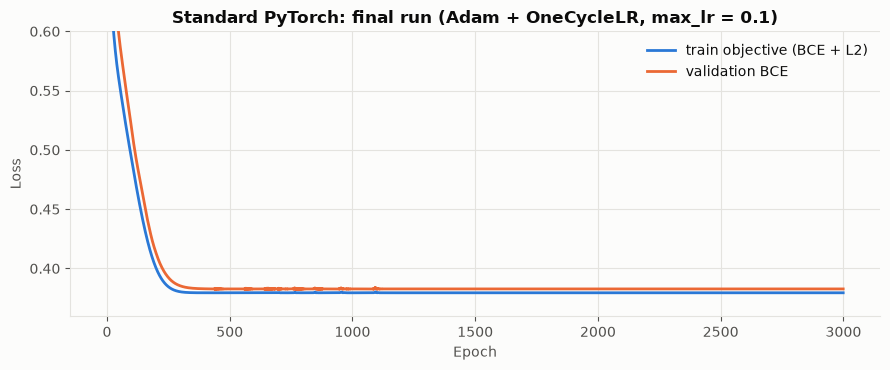

In [25]:
# Choose the max_lr with the lowest final VALIDATION loss. The final run uses the same epoch budget,
# so OneCycleLR produces exactly the schedule the max_lr was chosen with.
STANDARD_OPT = "Adam + OneCycleLR"
STANDARD_LR = float(standard_table.dropna().sort_values("final validation BCE").iloc[0]["max_lr"])
STANDARD_EPOCHS = SWEEP_EPOCHS
print(f"Chosen: {STANDARD_OPT} with max_lr = {STANDARD_LR}, training for {STANDARD_EPOCHS} epochs")

std_model, std_hist = train_standard(Xt_train, yt_train, STANDARD_LR, STANDARD_EPOCHS, LAMBDA, Xt_val, yt_val)
p_val_std = std_model.predict_proba(Xt_val).numpy()
p_test_std = std_model.predict_proba(Xt_test).numpy()
print(f"Final train objective: {std_hist['train_objective'][-1]:.6f}  (sklearn: {SK_OBJECTIVE:.6f})")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(std_hist["train_objective"], color=BLUE, label="train objective (BCE + L2)")
ax.plot(std_hist["val_bce"], color=ORANGE, label="validation BCE")
ax.set_ylim(min(std_hist["train_objective"]) - 0.02, 0.6)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title(f"Standard PyTorch: final run ({STANDARD_OPT}, max_lr = {STANDARD_LR})")
ax.legend()
finish(fig, "14_standard_final_curve")

## 6. Three-method comparison

If all three minimise the same convex objective on the same data, they should land on (almost) **the same
weights**, and therefore the same predictions. Small remaining differences can come from: (1) a PyTorch loop that
stopped before fully converging; (2) `float32` (PyTorch) vs. `float64` (scikit-learn) arithmetic; (3) different
starting points (zeros vs. `nn.Linear`'s random initialisation), which only matters if training stopped early.

In [26]:
sk_w, sk_b = sk_model.coef_[0], sk_model.intercept_[0]
man_w, man_b = manual_w.numpy(), manual_b.item()
std_w = std_model.linear.weight.detach().numpy()[0]
std_b = std_model.linear.bias.item()

coef_table = pd.DataFrame({"scikit-learn": np.append(sk_w, sk_b),
                           "Manual PyTorch": np.append(man_w, man_b),
                           "Standard PyTorch": np.append(std_w, std_b)},
                          index=FEATURES + ["(bias)"])
coef_table["max abs difference"] = coef_table.max(axis=1) - coef_table.min(axis=1)
display(coef_table.sort_values("scikit-learn", key=abs, ascending=False).round(4))

# How different are the predicted probabilities on the test set?
pairs = {"sklearn vs manual": np.abs(p_test_sk - p_test_manual),
         "sklearn vs standard": np.abs(p_test_sk - p_test_std),
         "manual vs standard": np.abs(p_test_manual - p_test_std)}
display(pd.DataFrame({k: {"max |Δp|": v.max(), "mean |Δp|": v.mean()} for k, v in pairs.items()}).T)

,scikit-learn,Manual PyTorch,Standard PyTorch,max abs difference
(bias),-1.7291,-1.7260,-1.7291,0.0031
city_Other_India,0.7859,0.7872,0.7859,0.0013
rel_price,0.4309,0.3656,0.4309,0.0653
log_locality_median_cost,0.3454,0.3434,0.3454,0.0021
cuisine_Raw_Meats,-0.2958,-0.2744,-0.2958,0.0214
log_locality_restaurants,0.2625,0.2638,0.2625,0.0012
cuisine_North_Indian,-0.2622,-0.2542,-0.2622,0.0079
cuisine_Chinese,-0.2385,-0.2323,-0.2385,0.0062
cuisine_Street_Food,0.2033,0.2132,0.2033,0.0099
cuisine_Italian,0.2028,0.2048,0.2028,0.0019


,max |Δp|,mean |Δp|
sklearn vs manual,1.364146e-02,1.146558e-03
sklearn vs standard,2.921621e-07,4.005023e-08
manual vs standard,1.364136e-02,1.146546e-03


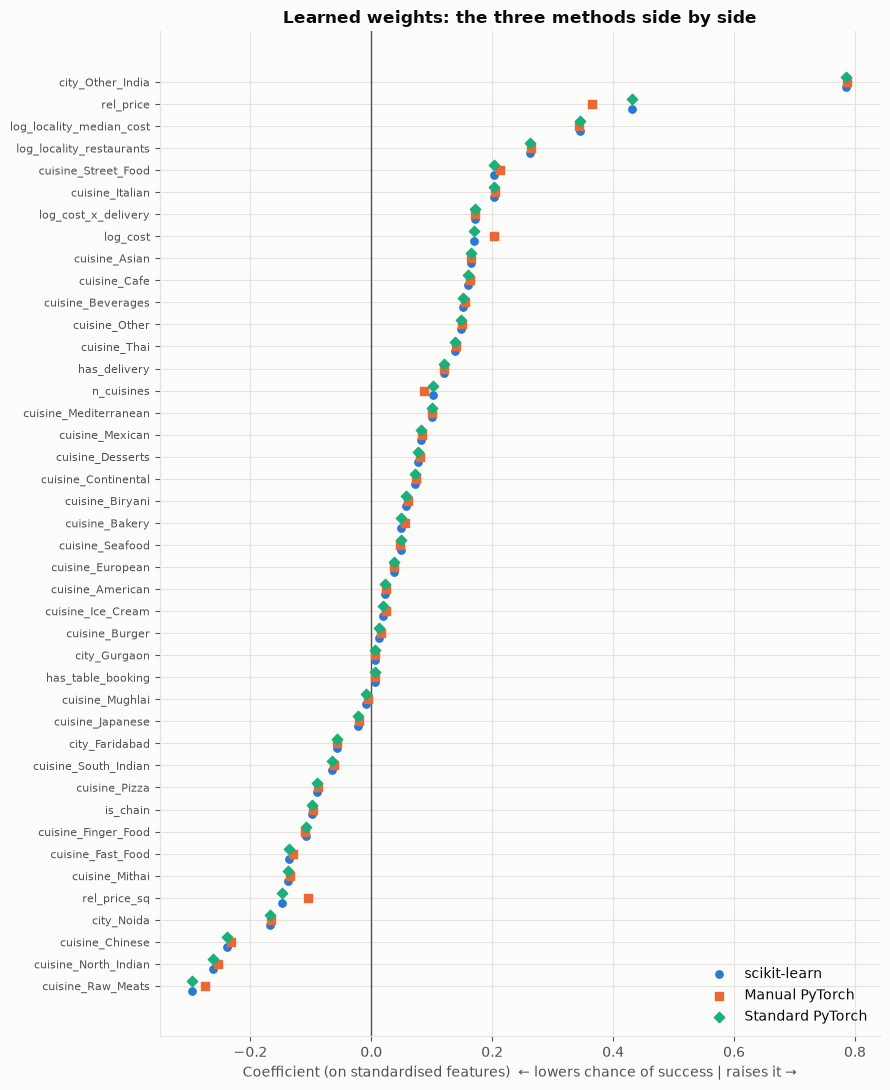

In [27]:
# Coefficients of all three methods side by side, sorted by the scikit-learn value.
# Weights are on STANDARDISED features: a weight of +0.5 means "one standard deviation
# more of this feature multiplies the odds of success by e^0.5 ≈ 1.65", holding everything else fixed.
order = coef_table.drop("(bias)").sort_values("scikit-learn").index
fig, ax = plt.subplots(figsize=(9, 11))
ypos = np.arange(len(order))
for offset, (name, color, marker) in zip([-0.22, 0, 0.22], [("scikit-learn", BLUE, "o"),
                                                           ("Manual PyTorch", ORANGE, "s"),
                                                           ("Standard PyTorch", AQUA, "D")]):
    ax.scatter(coef_table.loc[order, name], ypos + offset, color=color, marker=marker, s=28, label=name, zorder=3)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(ypos, order, fontsize=8)
ax.set_xlabel("Coefficient (on standardised features)  ← lowers chance of success | raises it →")
ax.set_title("Learned weights: the three methods side by side")
ax.legend(loc="lower right")
finish(fig, "15_coefficients_three_methods")

In [28]:
# Metrics of every model on validation and test, next to the baseline.
models_val = {"Baseline (constant)": baseline_val, "scikit-learn": p_val_sk,
              "Manual PyTorch": p_val_manual, "Standard PyTorch": p_val_std}
models_test = {"Baseline (constant)": baseline_test, "scikit-learn": p_test_sk,
               "Manual PyTorch": p_test_manual, "Standard PyTorch": p_test_std}
metrics_val = pd.DataFrame({k: evaluate(y_val, p) for k, p in models_val.items()}).T
metrics_test = pd.DataFrame({k: evaluate(y_test, p) for k, p in models_test.items()}).T
print("VALIDATION")
display(metrics_val.round(4))
print("TEST (touched once, final numbers)")
display(metrics_test.round(4))

VALIDATION


,log loss,ROC-AUC,avg precision,Brier
Baseline (constant),0.5253,0.5000,0.2188,0.1709
scikit-learn,0.3827,0.8399,0.6450,0.1182
Manual PyTorch,0.3825,0.8399,0.6451,0.1181
Standard PyTorch,0.3827,0.8399,0.6450,0.1182


TEST (touched once, final numbers)


,log loss,ROC-AUC,avg precision,Brier
Baseline (constant),0.5253,0.5000,0.2188,0.1709
scikit-learn,0.3562,0.8693,0.6850,0.1118
Manual PyTorch,0.3565,0.8694,0.6853,0.1119
Standard PyTorch,0.3562,0.8693,0.6850,0.1118


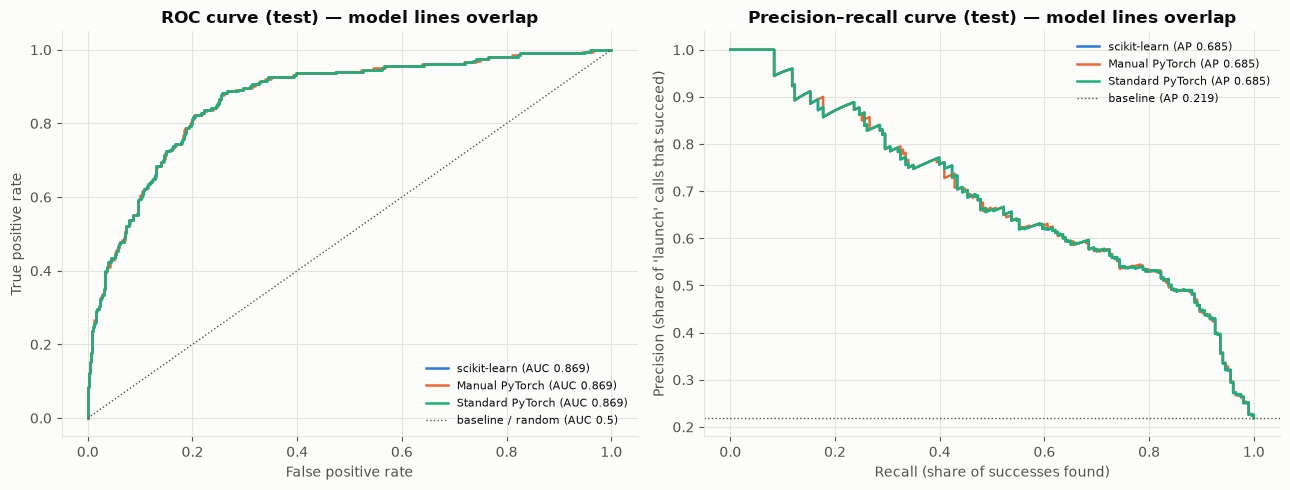

In [29]:
# ROC and precision-recall curves on the test set. The three models should sit on top of each other.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in ["scikit-learn", "Manual PyTorch", "Standard PyTorch"]:
    p = models_test[name]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], linewidth=1.8, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], linewidth=1.8, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=INK_2, linestyle=":", linewidth=1, label="baseline / random (AUC 0.5)")
axes[1].axhline(y_test.mean(), color=INK_2, linestyle=":", linewidth=1, label=f"baseline (AP {y_test.mean():.3f})")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test) — model lines overlap")
axes[1].set(xlabel="Recall (share of successes found)", ylabel="Precision (share of 'launch' calls that succeed)",
            title="Precision–recall curve (test) — model lines overlap")
for ax in axes:
    ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
finish(fig, "16_roc_pr_curves")

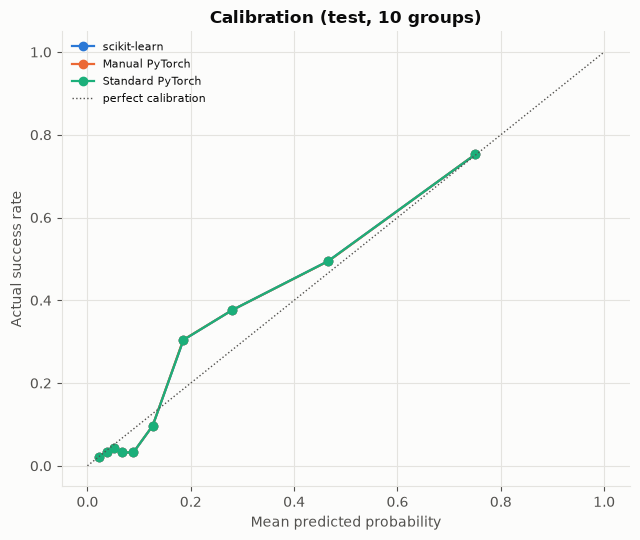

In [30]:
# Calibration: when the model says "30%", do ~30% of those restaurants actually succeed?
# Restaurants are sorted by predicted probability and cut into 10 equal-sized groups;
# for each group we plot mean predicted probability vs. actual success rate.
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name in ["scikit-learn", "Manual PyTorch", "Standard PyTorch"]:
    p = models_test[name]
    groups = pd.qcut(p, 10, labels=False, duplicates="drop")
    cal = pd.DataFrame({"p": p, "y": y_test, "g": groups}).groupby("g").mean()
    ax.plot(cal["p"], cal["y"], marker="o", markersize=6, color=MODEL_COLORS[name], linewidth=1.6, label=name)
ax.plot([0, 1], [0, 1], color=INK_2, linestyle=":", linewidth=1, label="perfect calibration")
ax.set(xlabel="Mean predicted probability", ylabel="Actual success rate", title="Calibration (test, 10 groups)")
ax.legend(fontsize=8)
finish(fig, "17_calibration")

## 7. Decision threshold from business costs

The model gives a probability; the company needs a **yes/no**: *launch this concept or not?* We launch when the
probability ≥ some threshold $t$. Each threshold produces four outcomes:

| | Actually succeeds | Actually doesn't |
|---|---|---|
| **Launch** (p ≥ t) | True positive ✓ | **False positive** = flop, costs `COST_FLOP` |
| **Skip** (p < t) | **False negative** = missed opportunity, costs `COST_MISSED` | True negative ✓ |

**Total cost(t) = FP × COST_FLOP + FN × COST_MISSED.** We choose $t$ on the **validation** set (lowest total cost)
and report it on the test set.

Theory check: for perfectly calibrated probabilities, the cost-minimising threshold is
$t^* = \frac{\text{COST\_FLOP}}{\text{COST\_FLOP} + \text{COST\_MISSED}}$. Launch only when the expected cost of
launching, $(1-p)\cdot\text{COST\_FLOP}$, is lower than the expected cost of skipping, $p\cdot\text{COST\_MISSED}$.

With a flop costing 3× a miss, that is 0.75: the model should launch only concepts it is quite confident about.

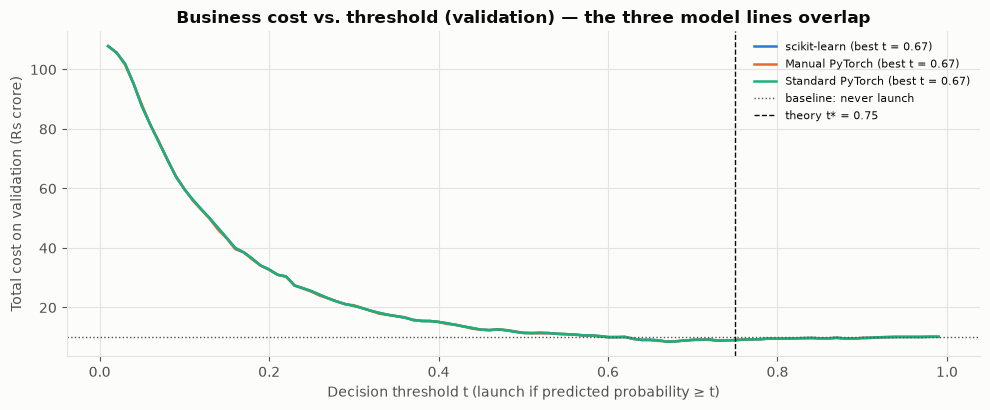

Chosen thresholds: {'scikit-learn': 0.67, 'Manual PyTorch': 0.67, 'Standard PyTorch': 0.67}


In [31]:
THRESHOLDS = np.round(np.arange(0.01, 1.0, 0.01), 2)
THEORY_T = COST_FLOP / (COST_FLOP + COST_MISSED)


def business_cost(y_true, prob, t):
    """Total rupee cost of launching every concept with prob >= t."""
    launch = prob >= t
    fp = np.sum(launch & (y_true == 0))
    fn = np.sum(~launch & (y_true == 1))
    return fp * COST_FLOP + fn * COST_MISSED


cost_curves, chosen_t = {}, {}
for name in ["scikit-learn", "Manual PyTorch", "Standard PyTorch"]:
    cost_curves[name] = np.array([business_cost(y_val, models_val[name], t) for t in THRESHOLDS])
    chosen_t[name] = float(THRESHOLDS[cost_curves[name].argmin()])
# Doing nothing (never launch) = every success is missed. This is the baseline's best decision.
never_launch_val = y_val.sum() * COST_MISSED

fig, ax = plt.subplots(figsize=(10, 4.2))
for name, curve in cost_curves.items():
    ax.plot(THRESHOLDS, curve / 1e7, color=MODEL_COLORS[name], linewidth=1.8, label=f"{name} (best t = {chosen_t[name]:.2f})")
ax.axhline(never_launch_val / 1e7, color=INK_2, linestyle=":", linewidth=1, label="baseline: never launch")
ax.axvline(THEORY_T, color=INK, linestyle="--", linewidth=1, label=f"theory t* = {THEORY_T:.2f}")
ax.set_xlabel("Decision threshold t (launch if predicted probability ≥ t)")
ax.set_ylabel("Total cost on validation (Rs crore)")
ax.set_title("Business cost vs. threshold (validation) — the three model lines overlap")
ax.legend(fontsize=8)
finish(fig, "18_cost_vs_threshold")
print("Chosen thresholds:", chosen_t)

,threshold,TP,FP,FN,TN,precision,recall,cost (Rs lakh)
model,,,,,,,,
scikit-learn,0.67,54,11,149,714,0.831,0.266,910.0
Manual PyTorch,0.67,54,11,149,714,0.831,0.266,910.0
Standard PyTorch,0.67,54,11,149,714,0.831,0.266,910.0
Baseline: never launch,NaN,0,0,203,725,NaN,0.000,1015.0


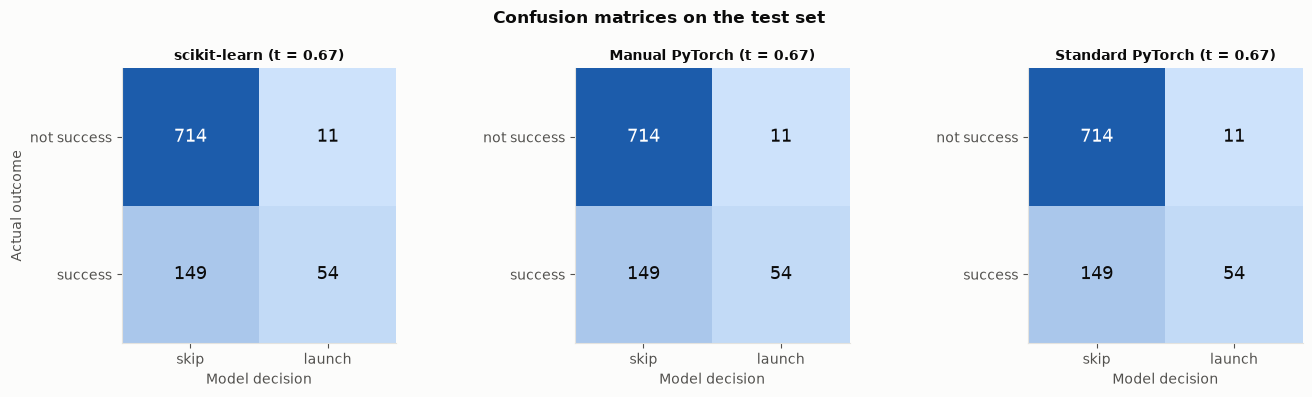

In [32]:
# Final decision quality on the TEST set, each model at its own validation-chosen threshold.
rows, cms = [], {}
for name in ["scikit-learn", "Manual PyTorch", "Standard PyTorch"]:
    t, p = chosen_t[name], models_test[name]
    tn, fp, fn, tp = confusion_matrix(y_test, (p >= t).astype(int), labels=[0, 1]).ravel()
    cms[name] = np.array([[tn, fp], [fn, tp]])
    rows.append({"model": name, "threshold": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
                 "cost (Rs lakh)": business_cost(y_test, p, t) / 1e5})
rows.append({"model": "Baseline: never launch", "threshold": None, "TP": 0, "FP": 0,
             "FN": int(y_test.sum()), "TN": int((y_test == 0).sum()), "precision": None, "recall": 0.0,
             "cost (Rs lakh)": y_test.sum() * COST_MISSED / 1e5})
decision_table = pd.DataFrame(rows).set_index("model")
display(decision_table.round(3))

# Confusion matrices (test). Rows = what actually happened, columns = what the model decided.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
blues = matplotlib.colors.LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#1c5cab"])
for ax, (name, cm) in zip(axes, cms.items()):
    ax.imshow(cm, cmap=blues)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else INK)
    ax.set_xticks([0, 1], ["skip", "launch"])
    ax.set_yticks([0, 1], ["not success", "success"])
    ax.set_xlabel("Model decision")
    ax.set_title(f"{name} (t = {chosen_t[name]:.2f})", fontsize=10)
    ax.grid(False)
axes[0].set_ylabel("Actual outcome")
fig.suptitle("Confusion matrices on the test set", fontweight="bold")
finish(fig, "19_confusion_matrices")

## 8. What the model says about the price sweet spot

The coefficients alone are hard to read, because changing the price moves **several** features at once
(`log_cost`, `rel_price`, `rel_price_sq`, `log_cost_x_delivery`). So we ask the trained model directly: for a
**cloud-kitchen concept** (delivery yes, no table booking, a new brand, located in the city's busiest locality),
what is the predicted probability of success at each price? If the curve rises and then falls, its peak is the
model's sweet spot for that cuisine and city. If it keeps rising to the edge of the chart, the model found no
sweet spot inside that price range.

Locality used per city: {'Gurgaon': 'DLF Phase 3', 'Noida': 'Sector 62'}


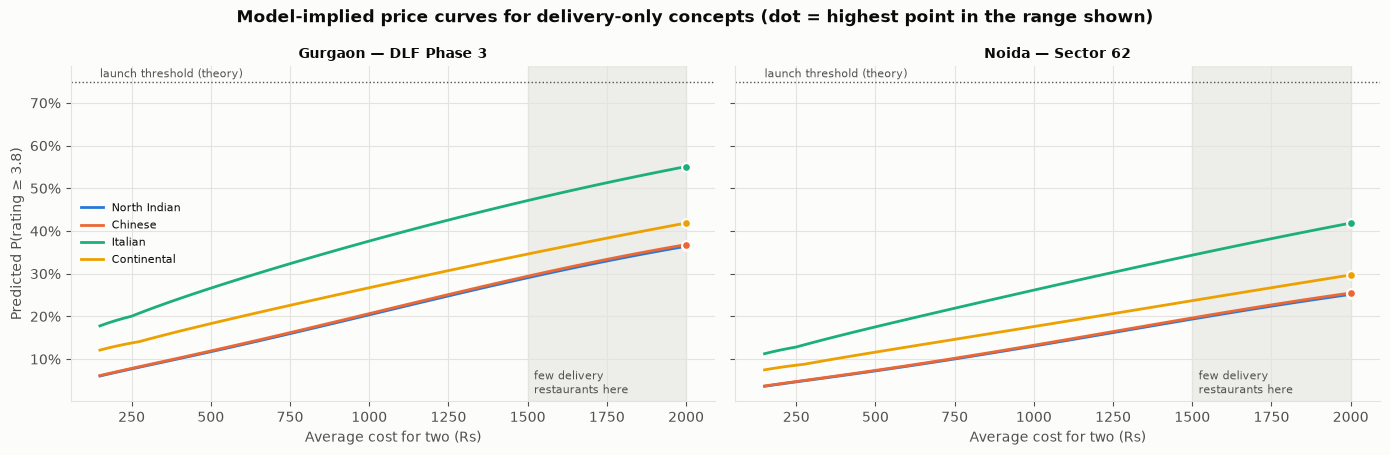

,city,cuisine,best cost for two (Rs),P(success) at best,P(success) at Rs 400
0,Gurgaon,North Indian,2000,0.364,0.101
1,Gurgaon,Chinese,2000,0.368,0.103
2,Gurgaon,Italian,2000,0.551,0.241
3,Gurgaon,Continental,2000,0.419,0.165
4,Noida,North Indian,2000,0.252,0.062
5,Noida,Chinese,2000,0.255,0.063
6,Noida,Italian,2000,0.419,0.157
7,Noida,Continental,2000,0.297,0.104


In [33]:
def concept_frame(cuisines, city, locality, costs, delivery="Yes", table_booking="No"):
    """One row per price for a hypothetical concept, in the same raw format as the dataset."""
    return pd.DataFrame({
        "Restaurant Name": "__new_cloud_kitchen_brand__",   # unknown name -> treated as a new, single-outlet brand
        "City": city, "Locality": locality, "Cuisines": cuisines,
        "Average Cost for two": costs, "Has Online delivery": delivery, "Has Table booking": table_booking,
    })


def predict_concepts(frame):
    """Probability of success from the scikit-learn model (the three agree; see Section 6)."""
    return sk_model.predict_proba(scaler.transform(P.build_features(frame, feature_params)))[:, 1]


# The busiest locality (most listed restaurants) of each target city.
busiest = {city: india.loc[india["City"] == city, "Locality"].value_counts().index[0] for city in ["Gurgaon", "Noida"]}
print("Locality used per city:", busiest)

COSTS = np.arange(150, 2001, 25)
# Cuisines that have their own feature column (a pooled 'Other' cuisine would not be specific).
SWEET_CUISINES = ["North Indian", "Chinese", "Italian", "Continental"]
# Above ~Rs 1,500 there are very few delivery restaurants in the data, so the curve there is
# mostly the model extrapolating its shape - it is shaded to make that visible.
THIN_DATA_FROM = 1500
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
sweet_rows = []
for ax, city in zip(axes, ["Gurgaon", "Noida"]):
    for color, cuisine in zip(SERIES, SWEET_CUISINES):
        p = predict_concepts(concept_frame(cuisine, city, busiest[city], COSTS))
        ax.plot(COSTS, p, color=color, linewidth=2, label=cuisine)
        k = int(np.argmax(p))
        ax.scatter([COSTS[k]], [p[k]], color=color, s=40, zorder=3, edgecolor=SURFACE, linewidth=1.5)
        sweet_rows.append({"city": city, "cuisine": cuisine, "best cost for two (Rs)": int(COSTS[k]),
                           "P(success) at best": p[k], "P(success) at Rs 400": p[np.searchsorted(COSTS, 400)]})
    ax.axvspan(THIN_DATA_FROM, COSTS[-1], color=GRID, alpha=0.6, zorder=0)
    ax.text(THIN_DATA_FROM + 20, 0.02, "few delivery\nrestaurants here", fontsize=8, color=INK_2)
    ax.axhline(THEORY_T, color=INK_2, linestyle=":", linewidth=1)
    ax.text(COSTS[0], THEORY_T + 0.01, "launch threshold (theory)", fontsize=8, color=INK_2)
    ax.set_title(f"{city} — {busiest[city]}", fontsize=10)
    ax.set_xlabel("Average cost for two (Rs)")
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axes[0].set_ylabel("Predicted P(rating ≥ 3.8)")
axes[0].legend(fontsize=8)
fig.suptitle("Model-implied price curves for delivery-only concepts (dot = highest point in the range shown)", fontweight="bold")
finish(fig, "20_sweet_spot_curves")
display(pd.DataFrame(sweet_rows).round(3))

rel_price term: a = 0.7251, rel_price^2 term: b = -0.0725  ->  curve is a hill (has a peak)
Vertex at relative price = 5.00x the cuisine norm (outside the observed range 0.25-3.71)


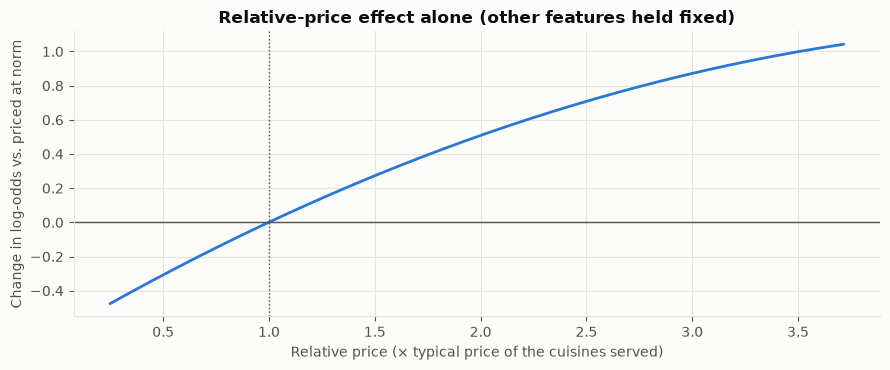

In [34]:
# The relative-price part of the model on its own: the contribution of rel_price and
# rel_price_sq to the log-odds, holding every other feature fixed. Converting the
# standardised weights back to the original scale: a * rel + b * rel^2, where
# a = w_rel / std_rel and b = w_sq / std_sq. If b < 0 the curve is a hill whose top
# is at rel* = -a / (2b), i.e. the estimated sweet spot in "times the cuisine norm".
i_rel, i_sq = FEATURES.index("rel_price"), FEATURES.index("rel_price_sq")
a = sk_w[i_rel] / scaler.scale_[i_rel]
b = sk_w[i_sq] / scaler.scale_[i_sq]
lo, hi = feature_params["rel_price_clip"]
rel_grid = np.linspace(lo, hi, 200)
contribution = a * rel_grid + b * rel_grid ** 2
contribution -= contribution[np.argmin(np.abs(rel_grid - 1.0))]   # 0 = priced exactly at the cuisine norm

shape = "hill (has a peak)" if b < 0 else "valley / no interior peak"
vertex = -a / (2 * b) if b != 0 else np.nan
print(f"rel_price term: a = {a:.4f}, rel_price^2 term: b = {b:.4f}  ->  curve is a {shape}")
print(f"Vertex at relative price = {vertex:.2f}x the cuisine norm "
      f"({'inside' if lo <= vertex <= hi else 'outside'} the observed range {lo:.2f}-{hi:.2f})")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(rel_grid, contribution, color=BLUE)
ax.axhline(0, color=INK_2, linewidth=1)
ax.axvline(1.0, color=INK_2, linestyle=":", linewidth=1)
ax.set_xlabel("Relative price (× typical price of the cuisines served)")
ax.set_ylabel("Change in log-odds vs. priced at norm")
ax.set_title("Relative-price effect alone (other features held fixed)")
finish(fig, "21_relative_price_effect")

## 9. Save everything the app needs

The app (`app.py`) must **never retrain**. It loads these files:

| File | Content |
|---|---|
| `artifacts/sklearn_model.joblib` | trained scikit-learn model |
| `artifacts/manual_torch.pt` | manual loop's `w` and `b` tensors |
| `artifacts/standard_torch.pt` | `state_dict` (weights) of the `nn.Module` |
| `artifacts/scaler.joblib` | the fitted `StandardScaler` (train means/stds) |
| `artifacts/feature_params.json` | typical prices, cuisine list, locality stats: everything `build_features` needs |
| `artifacts/predictions.csv` | validation + test restaurants with all three models' probabilities |
| `artifacts/train_table.csv` | training restaurants (raw columns + engineered features) for distribution plots |
| `artifacts/summary.json` | chosen hyperparameters, thresholds, costs, metrics, loss histories |

In [35]:
joblib.dump(sk_model, ARTIFACT_DIR / "sklearn_model.joblib")
joblib.dump(scaler, ARTIFACT_DIR / "scaler.joblib")
torch.save({"w": manual_w, "b": manual_b}, ARTIFACT_DIR / "manual_torch.pt")
torch.save(std_model.state_dict(), ARTIFACT_DIR / "standard_torch.pt")
with open(ARTIFACT_DIR / "feature_params.json", "w") as f:
    json.dump(feature_params, f, indent=1)

raw_cols = ["Restaurant Name", "City", "Locality", "Cuisines", "Average Cost for two",
            "Has Online delivery", "Has Table booking", "Aggregate rating", "success"]
pred_frames = []
for split, df, ps in [("validation", val_df, (p_val_sk, p_val_manual, p_val_std)),
                      ("test", test_df, (p_test_sk, p_test_manual, p_test_std))]:
    out = df[raw_cols].copy()
    out["split"] = split
    out["p_sklearn"], out["p_manual"], out["p_standard"] = ps
    pred_frames.append(out)
pd.concat(pred_frames).to_csv(ARTIFACT_DIR / "predictions.csv", index=False)

pd.concat([train_df[raw_cols].reset_index(drop=True), X_train_raw.reset_index(drop=True)], axis=1) \
    .to_csv(ARTIFACT_DIR / "train_table.csv", index=False)

summary = {
    "success_rating": P.SUCCESS_RATING,
    "cost_flop": COST_FLOP, "cost_missed": COST_MISSED,
    "theory_threshold": THEORY_T,
    "chosen_thresholds": chosen_t,
    "best_C": BEST_C, "lambda": LAMBDA,
    "manual": {"lr": MANUAL_LR, "epochs": MANUAL_EPOCHS, "train_objective": manual_hist["train_objective"],
               "val_bce": manual_hist["val_bce"]},
    "standard": {"optimizer": STANDARD_OPT, "max_lr": STANDARD_LR, "epochs": STANDARD_EPOCHS,
                 "train_objective": std_hist["train_objective"], "val_bce": std_hist["val_bce"],
                 "lr_schedule": std_hist["lr"]},
    "sklearn_objective": SK_OBJECTIVE,
    "baseline_rate": float(base_rate),
    "metrics_val": metrics_val.to_dict(orient="index"),
    "metrics_test": metrics_test.to_dict(orient="index"),
    "split_sizes": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
}
with open(ARTIFACT_DIR / "summary.json", "w") as f:
    json.dump(summary, f)

print("Saved:", ", ".join(sorted(p.name for p in ARTIFACT_DIR.iterdir())))

Saved: feature_params.json, manual_torch.pt, predictions.csv, scaler.joblib, sklearn_model.joblib, standard_torch.pt, summary.json, train_table.csv
